In [92]:
#importing req. Lib.
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.feature_extraction.text import CountVectorizer
from wordcloud import WordCloud, STOPWORDS
nltk.download('stopwords')
from nltk.tokenize import sent_tokenize, word_tokenize
spanish_sw = set(stopwords.words('spanish'))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\juanc\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [93]:
df=pd.read_csv('../data/MIET EDM.csv')
data=df.sample(frac=5, replace=True, random_state=1)
data.head()

,Edad,Edad0,Edad1,Edad2,Genero,Postgrado,Residencia,Interes,Empleo,Empleo0,Empleo1,Modo,Modo1,Modo0,Motivadores,Conocimientos,Atributos
37,Menos de 25,0,0,0,0,0,0,0,Independiente / Emprendedor,1,0,Presencial,0,0,Aumentar mi remuneracion;Adquirir conocimiento...,Innovacion y desarrollo de productos;Liderazgo...,Prestigio académico de la institución;Costo to...
107,Menos de 25,0,0,0,0,0,0,1,Otra,0,0,Semipresencial (una actividad al trimestre),0,1,Avanzar en mi carrera profesional;,Innovacion y desarrollo de productos;Financiam...,Prestigio académico de la institución;Redes de...
12,45 o mas,0,0,1,1,1,1,1,Independiente / Emprendedor,1,0,100% online,1,0,Potenciar mi emprendimiento;Adquirir conocimie...,Propiedad intelectual y patentes;Liderazgo y g...,Costo total del programa;Duracion del programa;
72,25-34,1,0,0,0,0,0,0,Dependiente jornada parcial,0,1,Semipresencial (una actividad al trimestre),0,1,Avanzar en mi carrera profesional;Potenciar mi...,Emprendimiento tecnologico;Innovacion y desarr...,Calidad del cuerpo docente;Costo total del pro...
9,45 o mas,0,0,1,0,0,1,0,Dependiente jornada completa,0,1,100% online,1,0,Avanzar en mi carrera profesional;,Liderazgo y gestión de equipos;,Prestigio académico de la institución;Costo to...


## **Wordcloud for positive reasons**

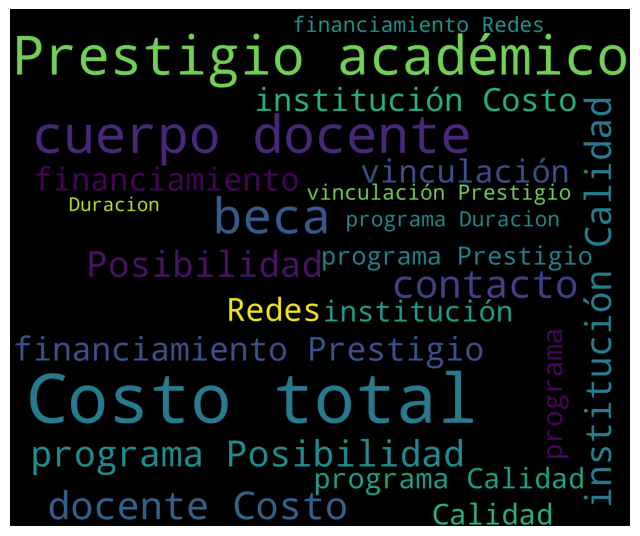

In [94]:
new_df=data[data['Interes']==0]
words = ' '.join(new_df['Motivadores'])
words = ' '.join(new_df['Conocimientos'])
words = ' '.join(new_df['Atributos'])
cleaned_word = " ".join([word for word in words.split()
                            if 'http' not in word
                                and not word.startswith('@')
                                and word != 'RT'
                            ])
wordcloud = WordCloud(stopwords=spanish_sw,
                      background_color='black',
                      width=3000,
                      height=2500
                     ).generate(cleaned_word)
plt.figure(1,figsize=(8, 8))
plt.imshow(wordcloud)
plt.axis('off')
plt.show()

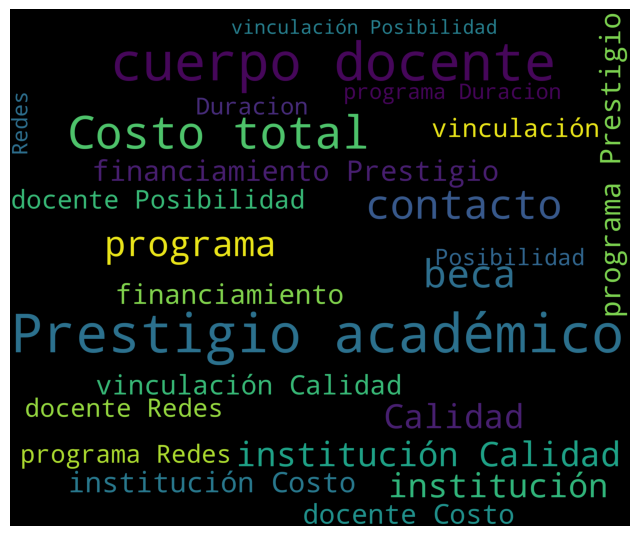

In [95]:
new_df=data[data['Interes']==1]
words = ' '.join(new_df['Motivadores'])
words = ' '.join(new_df['Conocimientos'])
words = ' '.join(new_df['Atributos'])
cleaned_word = " ".join([word for word in words.split()
                            if 'http' not in word
                                and not word.startswith('@')
                                and word != 'RT'
                            ])
wordcloud = WordCloud(stopwords=spanish_sw,
                      background_color='black',
                      width=3000,
                      height=2500
                     ).generate(cleaned_word)
plt.figure(1,figsize=(8, 8))
plt.imshow(wordcloud)
plt.axis('off')
plt.show() 

Wordcloud for Negative sentiments of tweets

## **Preprocessing the tweet text data**

Now, we will clean the tweet text data and apply classification algorithms on it

In [96]:
def tweet_to_words(tweet):
    letters_only = re.sub(r'#([A-Za-z_À-ÿ]+)', " ",tweet)
    words = letters_only.lower().split()
    stops = set(stopwords.words("spanish"))
    meaningful_words = [w for w in words if not w in stops]
    return( " ".join( meaningful_words ))

In [97]:
nltk.download('stopwords')
!data['Total'] = words
data['clean_tweet']=data['Atributos'].apply(lambda x: tweet_to_words(x))
data['clean_tweet'] = data['clean_tweet'].str.replace(r';', ' ', regex=True)
data['clean_tweet'].head()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\juanc\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
"data['Total']" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.


37     prestigio académico institución costo total pr...
107    prestigio académico institución redes contacto...
12               costo total programa duracion programa 
72     calidad cuerpo docente costo total programa du...
9      prestigio académico institución costo total pr...
Name: clean_tweet, dtype: object

# **Vectorization**

In [98]:
x = data.clean_tweet
y = data.Interes

print(len(x), len(y))

550 550


### The data is split in the standard 80,20 ratio

In [99]:
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=42)
print(len(x_train), len(y_train))
print(len(x_test), len(y_test))

412 412
138 138


In [100]:
vect_tunned = CountVectorizer(ngram_range=(2,3), min_df=1, max_df=0.95, max_features=30)
vect_tunned.fit(x_train)
x_train_dtm = vect_tunned.transform(x_train)
x_test_dtm = vect_tunned.transform(x_test)

# **Model Building (Support Vector Machine)**

In [101]:
#training RF with vectorized data
model = RandomForestClassifier(n_estimators=200, random_state=10)
model.fit(x_train_dtm, y_train)
#predicting output for test data
pred = model.predict(x_test_dtm)

In [102]:
#accuracy score
accuracy_score(y_test,pred)

0.8188405797101449

In [103]:
#building confusion matrix
cm = confusion_matrix(y_test, pred)
cm

array([[61, 16],
       [ 9, 52]])

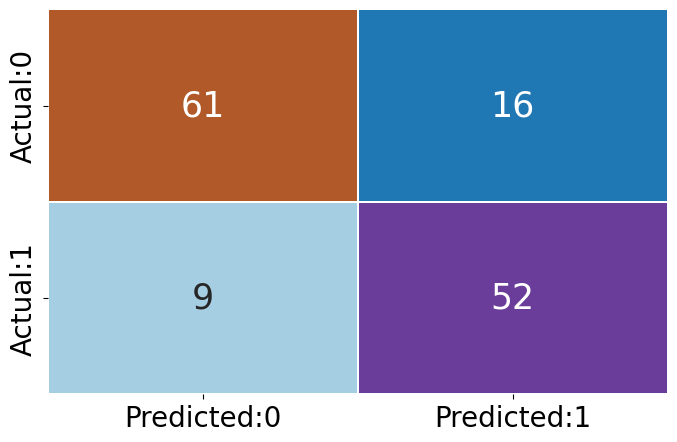

In [104]:
#defining the size of the canvas
plt.rcParams['figure.figsize'] = [8,5]
#confusion matrix to DataFrame
conf_matrix = pd.DataFrame(data = cm,columns = ['Predicted:0','Predicted:1',], index = ['Actual:0','Actual:1',])
#plotting the confusion matrix
sns.heatmap(conf_matrix, annot = True, fmt = 'd', cmap = 'Paired', cbar = False,linewidths = 0.1, annot_kws = {'size':25})
plt.xticks(fontsize = 20)
plt.yticks(fontsize = 20)
plt.show()


In [105]:
print(classification_report(y_test,pred))

              precision    recall  f1-score   support

           0       0.87      0.79      0.83        77
           1       0.76      0.85      0.81        61

    accuracy                           0.82       138
   macro avg       0.82      0.82      0.82       138
weighted avg       0.82      0.82      0.82       138



                            Feature  Importance
15                duracion programa    0.137273
4                    calidad cuerpo    0.053452
7                       costo total    0.044150
21  posibilidad beca financiamiento    0.042863
5            calidad cuerpo docente    0.039064
28                   total programa    0.037563
9                    cuerpo docente    0.037507
27       redes contacto vinculación    0.037178
3               beca financiamiento    0.036445
26                   redes contacto    0.036150


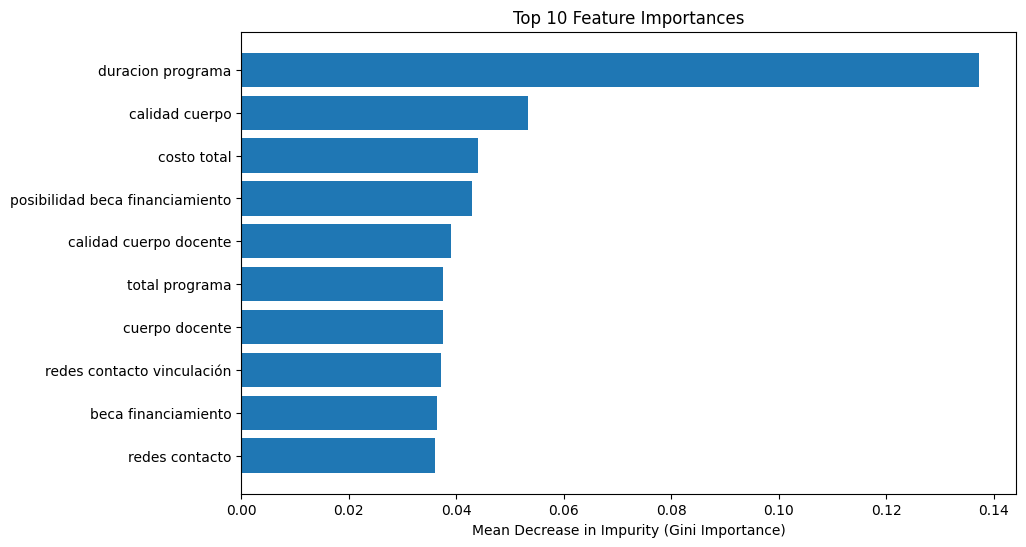

In [106]:
importances = model.feature_importances_
feature_names = vect_tunned.get_feature_names_out()

rf_importances = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(rf_importances.head(10))

# 4. Plot the results
plt.figure(figsize=(10, 6))
plt.barh(rf_importances['Feature'].head(10), rf_importances['Importance'].head(10))
plt.gca().invert_yaxis()  # Put the highest importance at the top
plt.xlabel('Mean Decrease in Impurity (Gini Importance)')
plt.title('Top 10 Feature Importances')
plt.show()